# Handwritten digits & math symbols — verified walkthrough

This notebook inspects the **included trained models**. Running all cells does not train or overwrite them.
It uses the same loading, preprocessing, augmentation and evaluation functions as the application and CLI.
The task is classification of **one symbol into 15 classes**.

Install `requirements-notebook.txt` first. Retraining is an optional, separate step described at the end.


In [1]:
from pathlib import Path
import json
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/data.py").is_file(), "Open this notebook from the repository or notebooks directory."
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from src.artifacts import load_metadata, load_saved_model
from src.augment import AUGMENTATIONS, augment_once
from src.config import DATA_DIR, MODELS_DIR, RESULTS_DIR
from src.data import load_dataset, split_data
from src.evaluate import evaluate_models, metric_differences
from src.models import gradcam_heatmap, overlay_heatmap

meta = load_metadata(MODELS_DIR)
print("Published run:", {key: meta[key] for key in ("seed", "max_epochs", "aug_per_image", "epochs_run")})


Published run: {'seed': 42, 'max_epochs': 12, 'aug_per_image': 2, 'epochs_run': {'CNN (real only)': 12, 'CNN (augmented)': 12}}


## 1. Data preparation and split

Images are converted to grayscale, normalized to light strokes on a dark background, cropped with their aspect ratio preserved and resized to 64×64. Transparent pixels are composited on white. Exact canonical duplicates and conflicting labels are removed before the stratified split.

There are no writer IDs. This is an image-level split, so it does not establish performance on unseen writers. See [dataset notes](../docs/DATASET.md).


{'files': 8384, 'unreadable': 0, 'duplicates_removed': 347, 'label_conflicts_removed': 1, 'kept': 8036}
Train / validation / test: 5785 643 1608


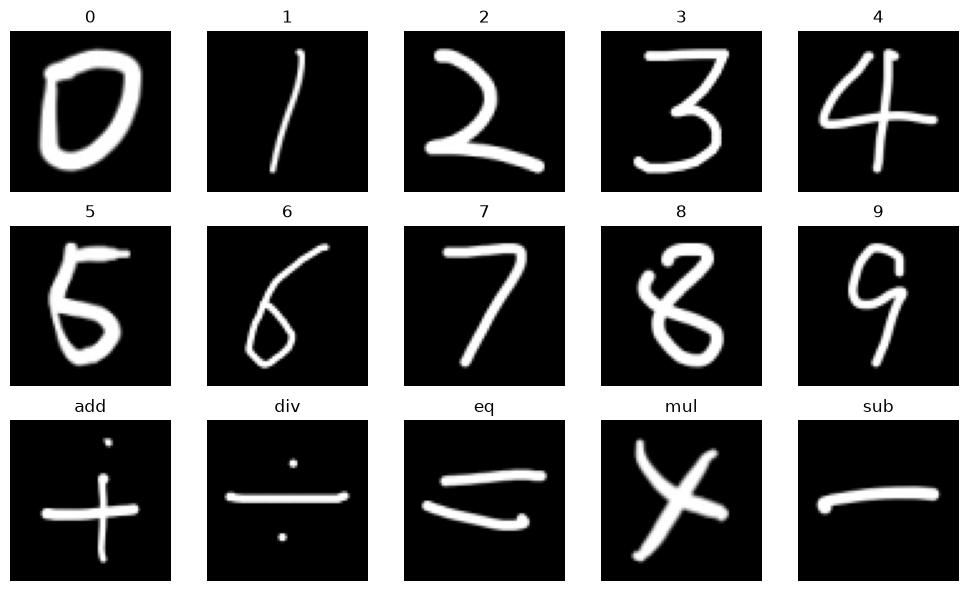

In [2]:
X, y, class_names, data_stats = load_dataset(DATA_DIR, size=tuple(meta["img_size"]))
assert class_names == meta["class_names"] and data_stats == meta["dataset"]
parts = split_data(X, y, seed=meta["seed"])
(X_tr, y_tr), (X_va, y_va), (X_te, y_te) = (parts[name] for name in ("train", "val", "test"))
assert [len(X_tr), len(X_va), len(X_te)] == [meta[key] for key in ("n_train", "n_val", "n_test")]
print(data_stats)
print("Train / validation / test:", len(X_tr), len(X_va), len(X_te))

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for label, ax in enumerate(axes.flat):
    ax.imshow(X_tr[np.flatnonzero(y_tr == label)[0]].squeeze(), cmap="gray")
    ax.set_title(class_names[label]); ax.axis("off")
fig.tight_layout()
plt.show()


## 2. Augmentation

Training used two extra copies per training image. The three families are stroke changes, occlusion and photometric changes. Below, the transformations are applied to a training example.

The robustness test uses one fixed-seed augmented copy of the held-out test set. It tests these transformation families, rather than arbitrary real-world image conditions.


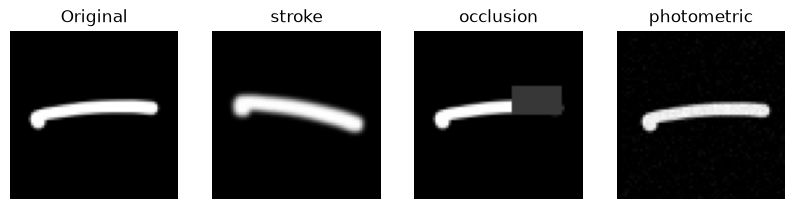

In [3]:
rng = np.random.default_rng(meta["seed"])
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
example = X_tr[0]
axes[0].imshow(example.squeeze(), cmap="gray"); axes[0].set_title("Original")
for ax, (name, transform) in zip(axes[1:], AUGMENTATIONS.items()):
    ax.imshow(transform(example, rng).squeeze(), cmap="gray"); ax.set_title(name)
for ax in axes:
    ax.axis("off")
plt.show()
X_te_aug = augment_once(X_te, seed=meta["seed"] + 1)


## 3. Verify the saved models

HOG + linear SVM is the classical baseline. The two CNNs share architecture, validation data and callbacks; one was trained on real images and the other on real plus augmented images.

This evaluates existing weights. It checks the published accuracy and macro F1 without running training or selecting a new model on the test set.


In [4]:
metrics, predictions = evaluate_models(MODELS_DIR, X_te, y_te, X_te_aug)
expected = json.loads((RESULTS_DIR / "metrics.json").read_text())
differences = metric_differences(metrics, expected)
assert not differences, "\n".join(differences)
rows = ["| Model | Clean accuracy | Clean macro F1 | Augmented accuracy | Augmented macro F1 |",
        "|---|---:|---:|---:|---:|"]
for name, values in metrics.items():
    clean, augmented = values["clean_test"], values["augmented_test"]
    rows.append(f"| {name} | {clean['accuracy']:.4f} | {clean['f1_macro']:.4f} | "
                f"{augmented['accuracy']:.4f} | {augmented['f1_macro']:.4f} |")
display(Markdown("\n".join(rows)))
print("All published metrics match.")


| Model | Clean accuracy | Clean macro F1 | Augmented accuracy | Augmented macro F1 |
|---|---:|---:|---:|---:|
| SVM (HOG) | 0.9639 | 0.9640 | 0.8427 | 0.8466 |
| CNN (real only) | 0.9950 | 0.9952 | 0.7121 | 0.7588 |
| CNN (augmented) | 0.9944 | 0.9946 | 0.9845 | 0.9849 |

All published metrics match.


## 4. Confusion matrix and actual errors

The augmented CNN is the demo default because it retains higher accuracy under the tested perturbations. The clean test still contains mistakes; the examples below show those mistakes rather than selected successful predictions.


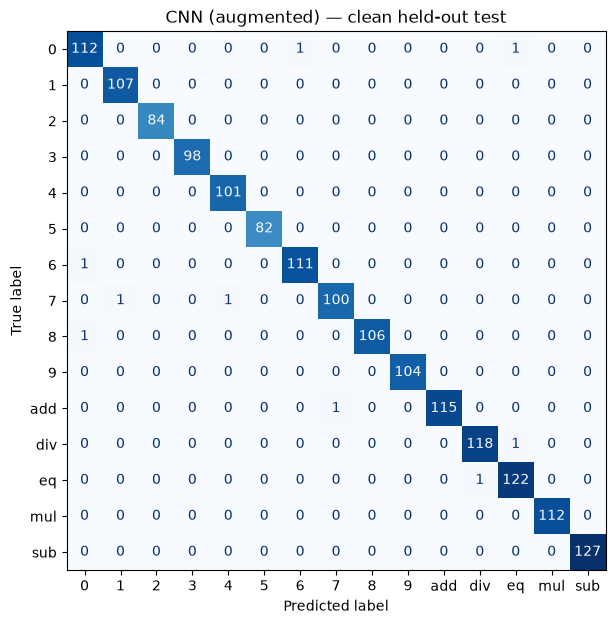

Misclassified: 9 / 1608


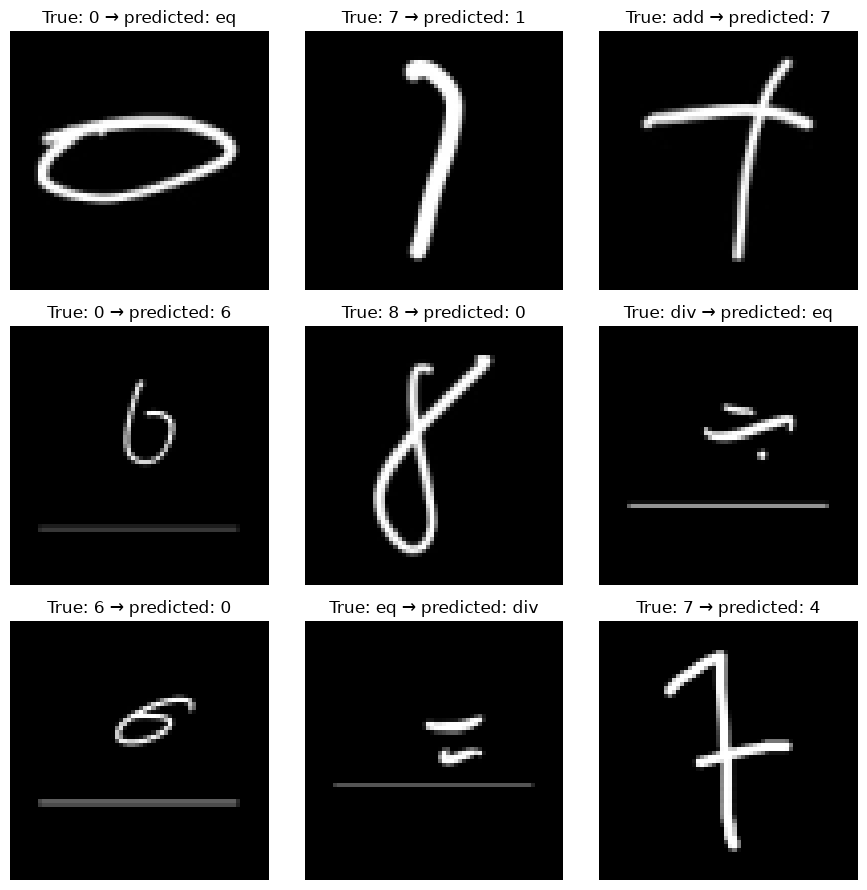

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
pred = predictions["CNN (augmented)"]["clean_test"]
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=class_names).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("CNN (augmented) — clean held-out test")
plt.show()

errors = np.flatnonzero(pred != y_te)
print(f"Misclassified: {len(errors)} / {len(y_te)}")
if len(errors):
    fig, axes = plt.subplots(int(np.ceil(len(errors) / 3)), 3, figsize=(9, 3 * int(np.ceil(len(errors) / 3))), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, index in zip(axes.flat, errors):
        ax.imshow(X_te[index].squeeze(), cmap="gray")
        ax.set_title(f"True: {class_names[y_te[index]]} → predicted: {class_names[pred[index]]}")
    fig.tight_layout()
    plt.show()


## 5. Grad-CAM

Grad-CAM visualizes gradient-based sensitivity for the predicted class. It helps inspect a prediction; it is not proof of a causal explanation or of correctness. These heatmaps show up to six of the errors above.


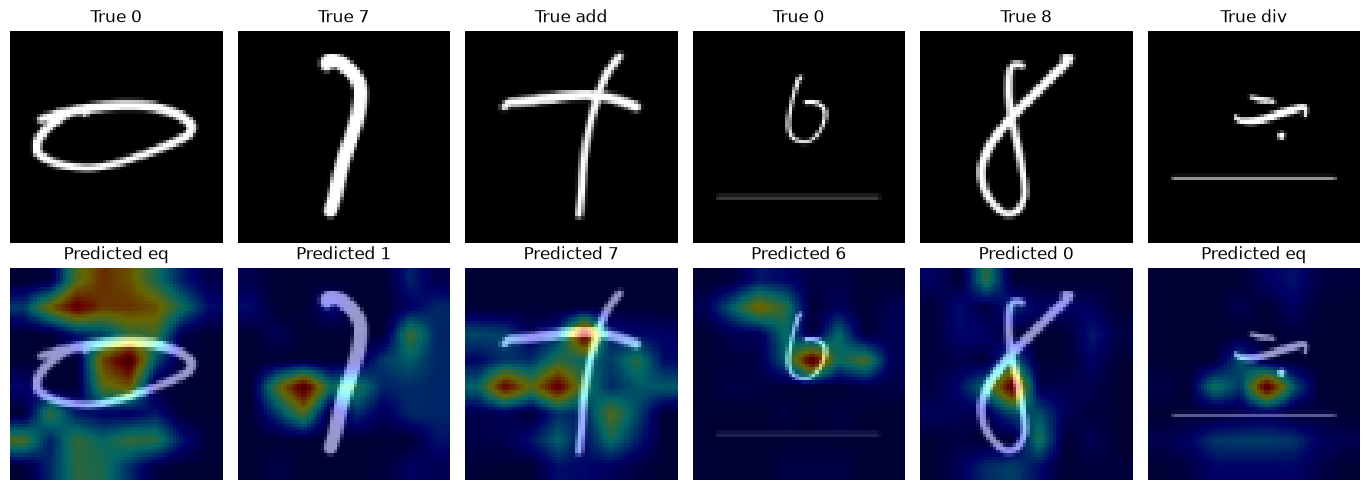

In [6]:
model = load_saved_model(MODELS_DIR, "CNN (augmented)")
indices = errors[:6] if len(errors) else np.arange(min(6, len(X_te)))
fig, axes = plt.subplots(2, len(indices), figsize=(2.3 * len(indices), 5), squeeze=False)
for column, index in enumerate(indices):
    heat = gradcam_heatmap(model, X_te[index], int(pred[index]))
    axes[0, column].imshow(X_te[index].squeeze(), cmap="gray")
    axes[0, column].set_title(f"True {class_names[y_te[index]]}")
    axes[1, column].imshow(overlay_heatmap(X_te[index], heat))
    axes[1, column].set_title(f"Predicted {class_names[pred[index]]}")
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
plt.show()


## 6. Interpretation and scope

- On the clean test, the two CNNs differ by one error. A single split does not establish a general advantage for either model on clean handwriting.
- Augmentation improves performance under the same perturbation families used during training. The augmented run also received about three times as many gradient updates, so this is not a compute-matched ablation.
- Only exact duplicates are removed. Similar drawings or shared writing styles may still appear in different splits.
- Softmax scores compare the known classes; arbitrary images are not reliably rejected. SVM provides a class without probabilities.
- Recognition of complete expressions, unfamiliar writers and photographs under arbitrary conditions is outside the validated scope.

## Optional: retrain the existing experiment

The shared defaults in `src/config.py` are 12 maximum epochs, seed 42 and two augmentations per training image. Training is implemented once in `src/train.py`; this notebook does not contain a second training loop.

From the repository root, choose a new pair of output directories:

```bash
python -m src.train --out runs/retrain/models --results runs/retrain/results
python -m src.evaluate --models runs/retrain/models --expected runs/retrain/results/metrics.json
```

The original `models/` and `results/` directories are protected. A repeated run refuses to overwrite nonempty output directories. Fresh training can differ with hardware or library versions; verification above checks the included weights.

## Run the demo

```bash
python app.py
```

Choose Draw or Upload, provide one symbol, select a model and press Predict. See the [README](../README.md) for installation and limitations.
